In [1]:
from traffic.core import Traffic
from mass import FuelEstimator
import numpy as np
import altair as alt
import pandas as pd
from flight import (
    FlightProfiles,
    FlightProfileGenerator,
    _to_df,
    gen_flight_profile,
    FlightPhaseEstimator,
    gentraj,
)
import openturns as ot
import openturns.viewer as viewer

ot.RandomGenerator.SetSeed(0)

/home/ach/sensiflow/flight.py:7: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [8]:
inputDesign = ot.Sample.ImportFromCSVFile("results/input/B77W_5600km.csv")
outputDesign = ot.Sample.ImportFromCSVFile("results/output/B77W_5600km.csv")
ac_type = "B77W"
mission = 5600


def test_openturns(X):
    # Transforming the input into np array
    # Xarray = np.array(X, copy=False)

    # Getting data from X
    # age = Xarray[:, 2]

    # Fuel Calculation with PDFs

    cumul = []
    for sample in X:
        load_factor = sample[0]
        weight_person = sample[1]
        descent_thrust = sample[2]
        cas_const_cl = sample[3]
        mach_const_cl = sample[4]
        cas_const_de = sample[5]
        mach_const_de = sample[6]
        range_cr = sample[7]
        alt_cr = sample[8]
        mach_cr = sample[9]

        traj = gentraj(
            ac_type,
            cas_const_cl=cas_const_cl,
            mach_const_cl=mach_const_cl,
            cas_const_de=cas_const_de,
            mach_const_de=mach_const_de,
            range_cr=range_cr,
            alt_cr=alt_cr,
            mach_cr=mach_cr,
            dt=60,
        )

        fe = FuelEstimator(
            ac_type=ac_type,
            passenger_mass=weight_person,
            load_factor=load_factor,
            descent_thrust=descent_thrust,
        )
        df = FlightPhaseEstimator()(_to_df(traj))
        fp = FlightProfiles.from_df(df)
        cumul.append([fe(fp).to_df().fc.iloc[-1]])

    return cumul

In [9]:
def get_dist(var):
    if var["statmodel"] == "beta":
        return ot.Beta(
            var["statmodel_params"][0],
            var["statmodel_params"][1],
            var["minimum"],
            var["maximum"],
        )
    elif var["statmodel"] == "norm":
        return ot.TruncatedDistribution(
            ot.Normal(*var["statmodel_params"]),
            var["minimum"],
            var["maximum"],
        )
    elif var["statmodel"] == "gamma":
        return ot.Gamma(
            var["statmodel_params"][0],
            1 / var["statmodel_params"][2],
            var["statmodel_params"][1],
        )

In [10]:
fun = ot.PythonFunction(10, 1, func=test_openturns, func_sample=test_openturns)
fpg = FlightProfileGenerator(ac_type=ac_type)
distribution = ot.ComposedDistribution(
    [
        ot.TruncatedDistribution(
            ot.Normal(0.819, 0.2), 1, ot.TruncatedDistribution.UPPER
        ),  # X0
        ot.TruncatedDistribution(
            (ot.Normal(0, 0.2) + 1) * 100, 80, ot.TruncatedDistribution.LOWER
        ),  # X1
        ot.TruncatedDistribution(
            ot.Normal(0.3, 0.2), 0.05, ot.TruncatedDistribution.LOWER
        ),  # X2
        get_dist(fpg.wrap.climb_const_vcas()),  # X3
        get_dist(fpg.wrap.climb_const_mach()),  # X4
        get_dist(fpg.wrap.descent_const_vcas()),  # X5
        get_dist(fpg.wrap.descent_const_mach()),  # X6
        (ot.Normal(0, 0.01) + 1) * mission,  # X7
        get_dist(fpg.wrap.cruise_alt()) * 1000,  # X8
        get_dist(fpg.wrap.cruise_mach()),  # X9
    ]
)

distribution.setDescription(
    [
        "Load Factor",
        "AWP",
        "Descent Thrust",
        "Cas Climbing",
        "Mach Climbing",
        "Cas Descent",
        "Mach Descent",
        "Cruise Range",
        "Cruise Altitude",
        "Cruise Mach",
    ]
)

Sample size:  48000
Output # 0
    First order indices:  [0.254073,0.136797,-0.00721369,-0.00721369,-0.000617583,-0.00780808,-0.00627553,0.0227604,0.517948,0.0666877]#10
    Total order indices:  [0.254926,0.145196,-1.74087e-11,-1.74087e-11,0.00360601,0.00314548,0.00373773,0.0231865,0.530091,0.0634417]#10
Agg. first order indices:  [0.254073,0.136797,-0.00721369,-0.00721369,-0.000617583,-0.00780808,-0.00627553,0.0227604,0.517948,0.0666877]#10
Agg. total order indices:  [0.254926,0.145196,-1.74087e-11,-1.74087e-11,0.00360601,0.00314548,0.00373773,0.0231865,0.530091,0.0634417]#10


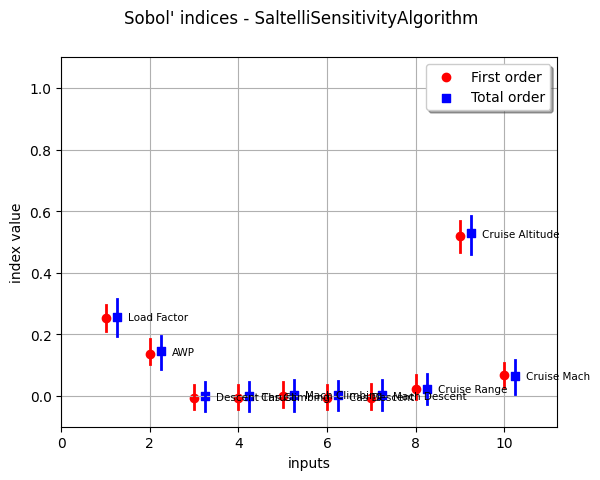

In [11]:
size = 4000
sie = ot.SobolIndicesExperiment(distribution, size)
inputDesign = sie.generate()
input_names = distribution.getDescription()
inputDesign.setDescription(input_names)
print("Sample size: ", inputDesign.getSize())

# %%

df_in = inputDesign.asDataFrame()
df_out = outputDesign.asDataFrame()

# %%

idx = df_out.y0[df_out.y0.isnull()].index
inputDesign = ot.Sample(df_in.drop(index=idx).values)
outputDesign = ot.Sample(df_out.drop(index=idx).values)

# %%
inputDesign.setDescription(distribution.getDescription())
sensitivityAnalysis = ot.SaltelliSensitivityAlgorithm(inputDesign, outputDesign, size)

# %%

output_dimension = fun.getOutputDimension()
for i in range(output_dimension):
    print("Output #", i)
    first_order = sensitivityAnalysis.getFirstOrderIndices(i)
    total_order = sensitivityAnalysis.getTotalOrderIndices(i)
    print("    First order indices: ", first_order)
    print("    Total order indices: ", total_order)

agg_first_order = sensitivityAnalysis.getAggregatedFirstOrderIndices()
agg_total_order = sensitivityAnalysis.getAggregatedTotalOrderIndices()
print("Agg. first order indices: ", agg_first_order)
print("Agg. total order indices: ", agg_total_order)
# %%

graph = sensitivityAnalysis.draw()
view = viewer.View(graph)

In [12]:
import altair as alt

points_1 = list(sensitivityAnalysis.getFirstOrderIndices())
points_t = list(sensitivityAnalysis.getTotalOrderIndices())
points = points_1 + points_t
lower_bound_1 = list(sensitivityAnalysis.getFirstOrderIndicesInterval().getLowerBound())
lower_bound_t = list(sensitivityAnalysis.getTotalOrderIndicesInterval().getLowerBound())
lower_bound = lower_bound_1 + lower_bound_t
upper_bound_1 = list(sensitivityAnalysis.getFirstOrderIndicesInterval().getUpperBound())
upper_bound_t = list(sensitivityAnalysis.getTotalOrderIndicesInterval().getUpperBound())
upper_bound = upper_bound_1 + upper_bound_t
names = list(distribution.getDescription()) * 2
cat = ["First Order"] * len(points_1) + ["Total Order"] * len(points_1)


source = pd.DataFrame(
    {
        "points": points,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "names": names,
        "cat": cat,
    }
)

# the base chart
base = alt.Chart(source)

means = (
    base.mark_circle(size=80)
    .encode(
        alt.X("points").scale(domain=(-0.15, 1)),
        alt.Y("cat", title=None),
        # alt.Row("names"),
        alt.Color("cat", title=f"2.d: {ac_type} - 5600km")
        # yOffset="cat:N",
    )
    .properties(width=600, height=30)
)

errorbars = base.mark_errorbar(thickness=3).encode(
    alt.X("lower_bound", title="index value"),
    alt.X2("upper_bound"),
    alt.Y("cat"),
    # alt.Row("names"),
    alt.Color("cat")
    # y=alt.Y("names"),
    # yOffset="cat:N",
    # color=alt.value("#4682b4"),
)
names = base.mark_text(align="right").encode(alt.Text("names"), x=alt.value(590))

chart = (
    (means + errorbars + names)
    .facet(row="names")
    .configure_axisY(labelFontSize=0, tickSize=0)
    .configure_axisX(titleAnchor="start")
    .configure_header(titleFontSize=0, labelAngle=0, labelFontSize=0)
    .configure_legend(orient="top", titleFontSize=20, titleLimit=2000)
    .configure_facet(spacing=0)
    .configure_text(font="Calibri")
    .properties(bounds="flush")
)
chart

alt.FacetChart(...)